> **Execução histórica:** estes resultados foram produzidos antes da correção da máscara SOURCE (bit 21). O flag identifica uma fonte conhecida, não um defeito. Execute novamente o comando do notebook para usar a máscara corrigida. Para o pipeline atualizado, consulte `06_sep_astrometria_psf_zogy.ipynb`.

# Teste com exposições reais do SPHEREx DR1

Os FITS foram baixados do IRSA por SIA2 e pelo serviço oficial de cutouts.
Não há fontes móveis injetadas neste experimento. Os recortes têm 0,25 grau;
as imagens originais têm 2040 × 2040 pixels. O detector 1 usa filtros LVF:
o comprimento de onda varia entre exposições, inclusive no mesmo detector.

Este é um teste exploratório. Um pico na busca não confirma um asteroide.

In [1]:
import json
from pathlib import Path

from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUTPUT = ROOT / "outputs/spherex"
report = json.loads((OUTPUT / "report.json").read_text())
print(report["experiment"])
print("Exposições:", report["n_exposures"])
print("Início UTC:", report["start_utc"])
print("Fim UTC:", report["end_utc"])
print("Duração [h]:", report["time_span_hours"])
print("Intervalos [s]:", report["intervals_seconds"])
print("Faixa de comprimento de onda no centro [µm, prévia]:", report["wavelength_range_um_preview"])
print("Asteroides confirmados:", report["confirmed_asteroids"])

REAL SPHEREx DR1 exposures, no injected moving source
Exposições: 8
Início UTC: 2025-10-31T07:37:29.170
Fim UTC: 2025-10-31T09:20:05.616
Duração [h]: 1.7101238880422898
Intervalos [s]: [128.93195506185293, 128.93005467485636, 128.93100455403328, 5382.861955510452, 128.93005404621363, 128.93100518267602, 128.92996792215854]
Faixa de comprimento de onda no centro [µm, prévia]: [0.7576945015683434, 1.1015059439141872]
Asteroides confirmados: 0


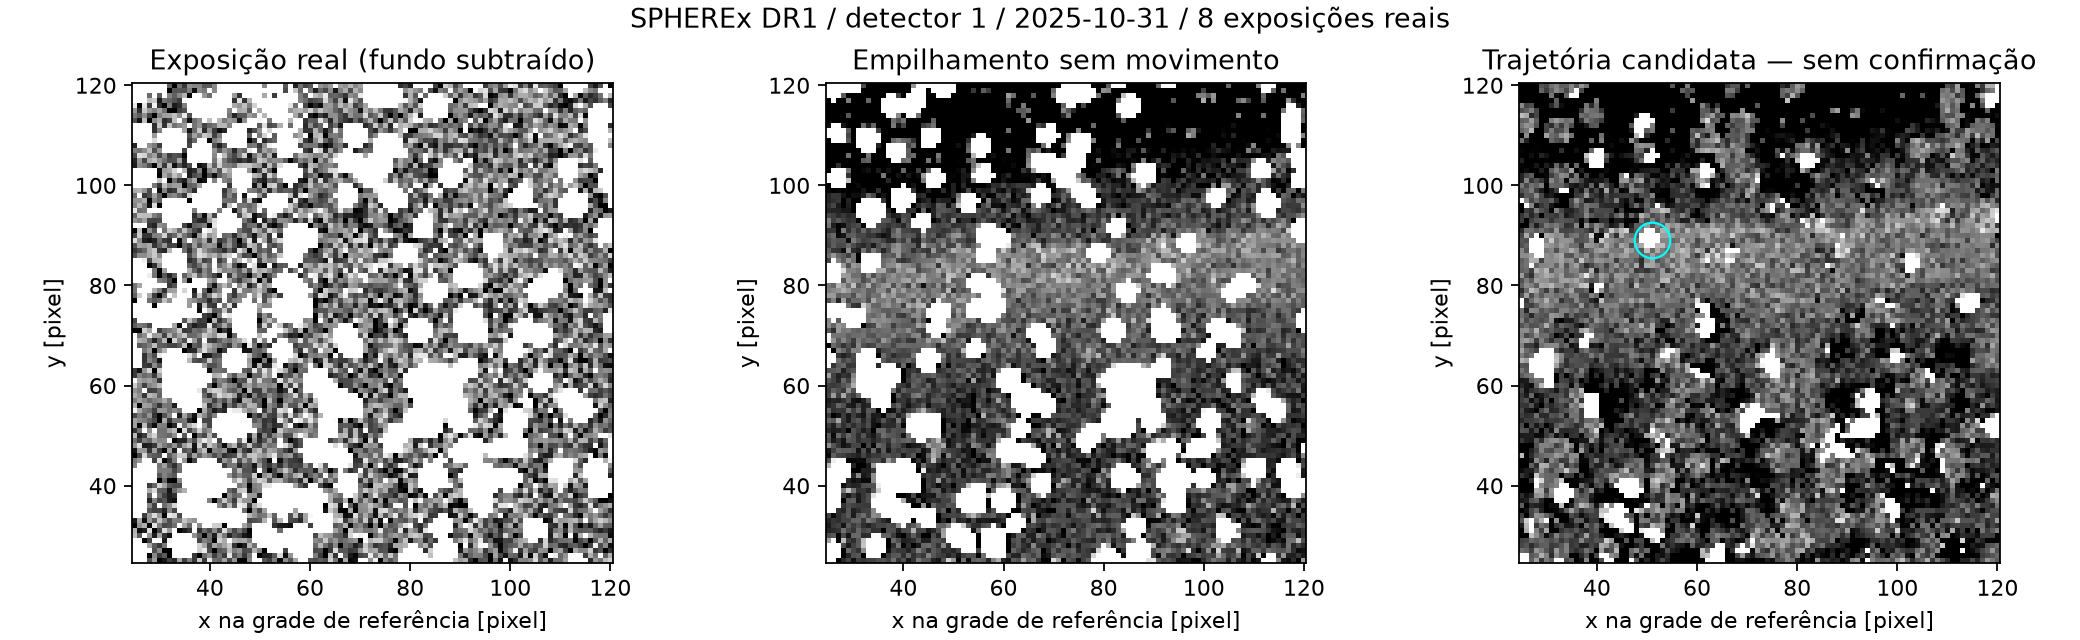

In [2]:
display(Image(filename=str(OUTPUT / "comparison.png")))

In [3]:
display(JSON(report))

<IPython.core.display.JSON object>

A figura mostra uma exposição real com fundo subtraído e pixels mascarados,
um empilhamento estacionário e o empilhamento da melhor hipótese móvel.
O círculo marca uma hipótese sem confirmação. Os escores dependem de um modelo
provisório de PSF gaussiana e não são significâncias globais.

A busca filtra os pixels originais e transforma as trajetórias via WCS, com
arredondamento para pixels nativos. Não interpola as imagens científicas para
calcular o escore. A visualização usa médias com pesos e pode repetir pixels.
A calibração espectral CWAVE/CBAND e as ePSFs ainda precisam entrar no modelo.

Para repetir, execute no terminal:
```bash
uv run spherex-tracking real
```
Os arquivos baixados são reutilizados. As URLs estão em `data/spherex/manifest.json`.
[Documentação oficial](https://irsa.ipac.caltech.edu/spherex-archive-documentation/spherex-data-access/).